# TASK 2

### Step 0: Install Libraries

In [56]:
%pip install numpy pandas scikit-learn prettytable matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


### Step 1: Import Libraries

In [57]:
# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [58]:
col_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
             'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# Load the data and apply the names
sample_data = pd.read_csv('processed.cleveland.data', header=None, names=col_names)

# Apply the constraint: Select only 4 input attributes + 1 output attribute
# (For example: Age, Sex, Chest Pain type, and Max Heart Rate)
sample_data = sample_data[['age', 'sex', 'cp', 'thalach', 'target']]

print(sample_data.head())

    age  sex   cp  thalach  target
0  63.0  1.0  1.0    150.0       0
1  67.0  1.0  4.0    108.0       2
2  67.0  1.0  4.0    129.0       1
3  37.0  1.0  3.0    187.0       0
4  41.0  0.0  2.0    172.0       0


### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [59]:
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(sample_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", sample_data["age"].count())
print("========================================\n")



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'thalach', 'target'], dtype='str')


Number of Instances in Sample Data: 303



#### Step 3.2: Pre-process Sample Data

In [60]:
# Remove any rows that contain a '?'
sample_data = sample_data[~sample_data.isin(['?']).any(axis=1)]

### Step 4: Feature Extraction
- Features are already Extracted
- No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
- As the data available is already encoded(Both input and output is already converted in Numeric Representation) and is in .data format instead of csv so Step 5 is already implemented

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [61]:

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=False keeps the original order of rows (no shuffling before splitting)
training_data, testing_data = train_test_split(
    sample_data,  
    test_size=0.2,
    random_state=0,
    shuffle=False
)

# Save the training and testing datasets to CSV files
training_data.to_csv('training-data.csv', index=False, header=True)
testing_data.to_csv('testing-data.csv', index=False, header=True)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [62]:
# Extract input vectors (features) from training data explicitly
input_vector_train = training_data[['age', 'sex', 'cp', 'thalach']]

# Extract output labels (target variable) from training data explicitly
output_label_train = training_data['target']

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### 6.3: Train the Support Vector Classifier

In [63]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., survived vs. not survived).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma='auto', random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [64]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
"""

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [65]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""
# Extract input vectors (features) from testing data explicitly
input_vector_test = testing_data[['age', 'sex', 'cp', 'thalach']]

# Extract output labels (target variable) from testing data explicitly
output_label_test = testing_data['target']

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [66]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [67]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data["Predictions"] = model_predictions
testing_data.to_csv(r'model-predictions.csv', index=False, header=True)
model_predictions = testing_data
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)



Predictions Returned by svc_trained_model:

      age  sex   cp  thalach  target  Predictions
242  49.0  0.0  4.0    163.0       0            0
243  61.0  1.0  1.0    145.0       2            0
244  60.0  0.0  3.0     96.0       0            0
245  67.0  1.0  4.0     71.0       2            0
246  58.0  1.0  4.0    156.0       2            0
247  47.0  1.0  4.0    118.0       1            0
248  52.0  1.0  4.0    168.0       3            0
249  62.0  1.0  2.0    140.0       0            0
250  57.0  1.0  4.0    126.0       0            0
251  58.0  1.0  4.0    105.0       1            0
252  64.0  1.0  4.0    105.0       0            0
253  51.0  0.0  3.0    157.0       0            0
254  43.0  1.0  4.0    181.0       0            0
255  42.0  0.0  3.0    173.0       0            0
256  67.0  0.0  4.0    142.0       0            0
257  76.0  0.0  3.0    116.0       0            0
258  70.0  1.0  2.0    143.0       0            0
259  57.0  1.0  2.0    141.0       1            0
260 

#### Step 7.4: Calculate the Accuracy Score

In [68]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["target"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.46


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)


Classification Report:

              precision    recall  f1-score   support

           0       0.49      0.97      0.65        29
           1       0.00      0.00      0.00        12
           2       0.00      0.00      0.00        13
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         2

    accuracy                           0.46        61
   macro avg       0.10      0.19      0.13        61
weighted avg       0.23      0.46      0.31        61


Confusion Matrix:

    0  1  2  3  4
0  28  1  0  0  0
1  12  0  0  0  0
2  11  2  0  0  0
3   5  0  0  0  0
4   1  0  1  0  0


C:\Users\DynaBook\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\DynaBook\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\DynaBook\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

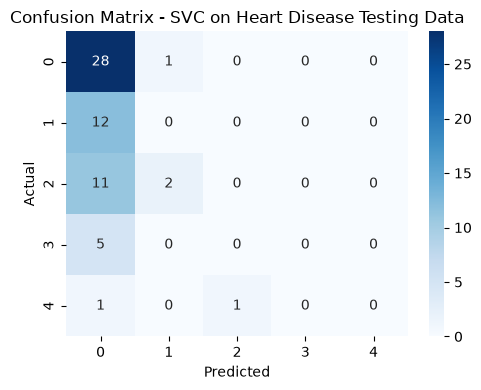

In [69]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small or imbalanced
datasets. This section adds the standard classification metrics:
- Precision: of everyone the model predicted in a class, how many actually were in it?
- Recall: of everyone who actually was in a class, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
# Removed target_names because the heart disease dataset predicts classes 0 through 4
print(classification_report(
    model_predictions["target"],
    model_predictions["Predictions"]
))

conf_matrix = confusion_matrix(model_predictions["target"], model_predictions["Predictions"])

# Let pandas handle the index and columns dynamically based on the classes present
conf_matrix_df = pd.DataFrame(conf_matrix)

print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
# Removed hardcoded tick labels so it automatically scales to the 5 classes
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [70]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(Age, Sex, CP, Thalach). In an interactive Jupyter session,
running this cell will prompt you for input(). For this notebook copy,
we pre-fill a demo patient so the notebook can also be read/run
top-to-bottom without needing to type anything.

To try your own values interactively, replace the four lines below with:
    age_input = float(input("Please enter Age (e.g., 63.0): ").strip())
    sex_input = float(input("Please enter Sex (1.0 for Male, 0.0 for Female): ").strip())
    cp_input = float(input("Please enter Chest Pain Type (1.0, 2.0, 3.0, 4.0): ").strip())
    thalach_input = float(input("Please enter Max Heart Rate (e.g., 150.0): ").strip())
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
age_input = 63.0
sex_input = 1.0
cp_input = 4.0
thalach_input = 150.0

print(f"Age: {age_input}, Sex: {sex_input}, CP: {cp_input}, Thalach: {thalach_input}")

Age: 63.0, Sex: 1.0, CP: 4.0, Thalach: 150.0


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [71]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input (entered as text)
and converts it into a structured feature vector (DataFrame).
"""

user_input = pd.DataFrame({
    'age': [age_input],
    'sex': [sex_input],
    'cp': [cp_input],
    'thalach': [thalach_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

    age  sex   cp  thalach
0  63.0  1.0  4.0    150.0


#### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)
- Data is already purely in numeric

#### Step 8.4: Load the Saved Model

In [72]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

model = pickle.load(open('svc_trained_model.pkl', 'rb'))

#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [73]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict the presence and severity of heart disease for a new patient.
"""

# We use the 'user_input' DataFrame we created in the previous step
predicted_target = model.predict(user_input)[0]

# 0 means no disease, 1-4 indicate varying levels of severity
if predicted_target == 0:
    prediction = "NO HEART DISEASE"
elif predicted_target == 1:
    prediction = "HEART DISEASE PRESENT (Severity 1)"
elif predicted_target == 2:
    prediction = "HEART DISEASE PRESENT (Severity 2)"
elif predicted_target == 3:
    prediction = "HEART DISEASE PRESENT (Severity 3)"
elif predicted_target == 4:
    prediction = "HEART DISEASE PRESENT (Severity 4)"
else:
    prediction = "UNKNOWN"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|        NO HEART DISEASE        |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [74]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert reviewing
this model's predictions on a few real-world-style cases.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Cardiologist", "Medical Student", "Medical Student"],
    "Case": [
        "63yo male, asymptomatic chest pain (CP=4), low max heart rate (Thalach=112) -> predicted HEART DISEASE PRESENT",
        "41yo female, typical angina (CP=1), high max heart rate (Thalach=172) -> predicted NO HEART DISEASE",
        "50yo female, non-anginal pain (CP=3), moderate max heart rate -> predicted HEART DISEASE PRESENT (unexpected)",
    ],
    "Feedback": [
        "Matches clinical expectations: older males with type 4 chest pain and lower max heart rates are generally higher risk.",
        "Matches clinical expectations: younger females achieving high maximum heart rates during exercise are generally lower risk.",
        "Surprising - the model may be over-relying on the limited 4 features. Adding more attributes like cholesterol or resting ECG might correct this.",
    ],
})
print(example_feedback.to_string(index=False))

       Reviewer                                                                                                           Case                                                                                                                                         Feedback
   Cardiologist 63yo male, asymptomatic chest pain (CP=4), low max heart rate (Thalach=112) -> predicted HEART DISEASE PRESENT                           Matches clinical expectations: older males with type 4 chest pain and lower max heart rates are generally higher risk.
Medical Student            41yo female, typical angina (CP=1), high max heart rate (Thalach=172) -> predicted NO HEART DISEASE                      Matches clinical expectations: younger females achieving high maximum heart rates during exercise are generally lower risk.
Medical Student  50yo female, non-anginal pain (CP=3), moderate max heart rate -> predicted HEART DISEASE PRESENT (unexpected) Surprising - the model may be over-relying on the limited

#### Step 9.2: Make a List of Potential Improvements

In [75]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Include all 13 available clinical attributes (e.g., cholesterol, resting blood pressure) instead of being constrained to just 4.",
    "Scale the numeric features (like Age and Max Heart Rate) using StandardScaler, as Support Vector Machines are highly sensitive to unscaled data.",
    "Simplify the target variable from 5 exact severity classes (0-4) to a simple binary outcome (0 = Healthy, 1 = Sick) to significantly boost model accuracy.",
    "Compare additional models (e.g., Random Forest, Gradient Boosting) that might handle this specific medical data better than a basic SVC."
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Include all 13 available clinical attributes (e.g., cholesterol, resting blood pressure) instead of being constrained to just 4.
2. Scale the numeric features (like Age and Max Heart Rate) using StandardScaler, as Support Vector Machines are highly sensitive to unscaled data.
3. Simplify the target variable from 5 exact severity classes (0-4) to a simple binary outcome (0 = Healthy, 1 = Sick) to significantly boost model accuracy.
4. Compare additional models (e.g., Random Forest, Gradient Boosting) that might handle this specific medical data better than a basic SVC.


#### Step 9.3: Improve the Model Based on Feedback

In [76]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the improvements listed above and re-run Steps 6-7 to confirm
the new model's accuracy improves before replacing the deployed model.
"""

print("Next version: retrain with all 13 clinical attributes and scaled numeric features, then re-evaluate before replacing svc_trained_model.pkl")

Next version: retrain with all 13 clinical attributes and scaled numeric features, then re-evaluate before replacing svc_trained_model.pkl
